# Global Lower Bound vs Exact Sequential Minimum

This notebook runs independently from the saved `inputs/benchmark_1d` and `inputs/benchmark_2d` phase CSVs. It does not read another notebook's outputs or regenerate input data.

Choose `RUN_MODE = "test"` or `"full"` in **Run configuration** below, then run all cells. The default is `"test"`. Install `requirements.txt` in the notebook's Python environment first.


## Definition from the paper

Source: *Quantum Sensor Resource Allocation for Spatial Field Discrimination*, supplied `QS_Alloc_TQC_Journal.pdf`, Section 3.2.1, equation (14), page 6:

$$N_{\mathrm{LB}}^{\mathrm{global}} = \min_{\boldsymbol n\in\mathbb Z_{\geq0}^M}\sum_m n_m
\quad\text{subject to}\quad \sum_m n_m|r_{ijm}|\geq\pi\quad\forall i<j.$$

We solve this integer program with SciPy/HiGHS, using the original principal phase gaps. Replacing $|r_{ijm}|$ with $\pi/N_{ijm}$ would change the problem because $N_{ijm}=\lceil\pi/|r_{ijm}|\rceil$ is rounded. We do not round the solution of a continuous relaxation.

The comparison quantity is the exact **sequential** allocation optimum $N_{\min}^{\mathrm{seq}}$ in Section 3.3, equation (15), computed by the repository's dynamic program. Every feasible sequential allocation satisfies (14), so $N_{\mathrm{LB}}^{\mathrm{global}}\leq N_{\min}^{\mathrm{seq}}$ instance by instance. The difference is a gap to a lower bound, **not** a demonstrated saving achievable by a global protocol. Equation (14) alone does not establish the existence of a common input state for global discrimination.

[Solver documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html): integer variables, zero requested relative MIP gap, and optimal termination are required. The rounded integer allocation is checked against every constraint (tolerance $10^{-8}$ after dividing by $\pi$); this is numerical optimization on floating-point phase data.

In [7]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

working_directory = Path.cwd().resolve()
PROJECT_DIRECTORY = (
    working_directory / "problem-1-zero-error"
    if (working_directory / "problem-1-zero-error").is_dir()
    else working_directory
)
SOURCE_DIRECTORY = PROJECT_DIRECTORY / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))
for module in ("run_config", "sensor_budget_analysis", "lower_bound", "phase_data", "optimal", "eval"):
    sys.modules.pop(module, None)
from sensor_budget_analysis import (
    run_budget_analysis, plot_budget_comparison, configure_style, save_figure,
)
print("Project directory:", PROJECT_DIRECTORY)


Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error


## Run configuration

- **`"test"` (default):** 96 cases across both dimensions, all three field families and all $K=3,\ldots,10$, using $M=3,6$ and replicate 1.
- **`"full"`:** all 11,520 saved benchmark cases. This may take several minutes.

Both modes use the same solvers. Test outputs are stored separately; final figures use full outputs only. Change the setting below and run all cells.


In [8]:
RUN_MODE = "full"  # Change to "full" for all 11,520 benchmark cases.

if RUN_MODE not in ("test", "full"):
    raise ValueError('RUN_MODE must be "test" or "full"')
print("Run mode:", RUN_MODE)
print("Expected standard benchmark cases:", 96 if RUN_MODE == "test" else 11_520)


Run mode: full
Expected standard benchmark cases: 11520


## Solve both budgets directly from the inputs

In [9]:
analysis = run_budget_analysis(
    PROJECT_DIRECTORY, include_lower_bound=True, run_mode=RUN_MODE,
)
rows = analysis["rows"]
summary = analysis["summary"]
OUTPUT_DIRECTORY = analysis["output_directory"]
assert all(row["N_LB"] <= row["N_min"] for row in rows)
print(f"Verified all {len(rows):,} paired instances.")
print("Output:", OUTPUT_DIRECTORY)

Run mode: full; selected 11,520 cases
benchmark_1d: 1/5,760 cases; 0.0s elapsed
benchmark_1d: 500/5,760 cases; 4.4s elapsed
benchmark_1d: 1,000/5,760 cases; 9.0s elapsed
benchmark_1d: 1,500/5,760 cases; 16.7s elapsed
benchmark_1d: 2,000/5,760 cases; 31.4s elapsed
benchmark_1d: 2,500/5,760 cases; 35.2s elapsed
benchmark_1d: 3,000/5,760 cases; 39.2s elapsed
benchmark_1d: 3,500/5,760 cases; 45.2s elapsed
benchmark_1d: 4,000/5,760 cases; 56.3s elapsed
benchmark_1d: 4,500/5,760 cases; 59.8s elapsed
benchmark_1d: 5,000/5,760 cases; 63.9s elapsed
benchmark_1d: 5,500/5,760 cases; 69.7s elapsed
benchmark_1d: 5,760/5,760 cases; 74.8s elapsed
benchmark_2d: 1/5,760 cases; 74.8s elapsed
benchmark_2d: 500/5,760 cases; 79.3s elapsed
benchmark_2d: 1,000/5,760 cases; 84.8s elapsed
benchmark_2d: 1,500/5,760 cases; 94.7s elapsed
benchmark_2d: 2,000/5,760 cases; 130.7s elapsed
benchmark_2d: 2,500/5,760 cases; 134.7s elapsed
benchmark_2d: 3,000/5,760 cases; 139.3s elapsed
benchmark_2d: 3,500/5,760 cases; 1

## Paired summary

In **full** mode, each point averages 720 matched instances at that dimension and $K$: 3 field families × 8 location counts ($M=3,\ldots,10$) × 30 realizations.

In **test** mode, each point averages just 6 matched instances: 3 families × 2 location counts ($M=3,6$) × replicate 1. This is a quick execution check, not the full benchmark result. The table shows the actual case counts.

Both curves use exactly the same selected instances. Means average individual integer optima and need not be integers. The saved $K,M$ table also reports comparisons at fixed location counts. These are empirical mean curves, not confidence bands.

In [10]:
def show_summary(rows, include_lb=False):
    header = r"| Dimension | K | Cases | Mean $N_{\min}^{\mathrm{seq}}$ |"
    separator = "|---|---:|---:|---:|"
    if include_lb:
        header += r" Mean $N_{\mathrm{LB}}^{\mathrm{global}}$ | Mean gap | Equal budgets (%) |"
        separator += "---:|---:|---:|"
    lines = [header, separator]
    for row in rows:
        line = (f"| {row['dimension']} | {row['K']} | {row['case_count']} | "
                f"{row['mean_N_min_opt']:.3f} |")
        if include_lb:
            line += (f" {row['mean_N_LB']:.3f} | {row['mean_sensor_gap']:.3f} | "
                     f"{100 * row['equal_budget_fraction']:.1f} |")
        lines.append(line)
    display(Markdown("\n".join(lines)))

show_summary(summary, include_lb=True)

| Dimension | K | Cases | Mean $N_{\min}^{\mathrm{seq}}$ | Mean $N_{\mathrm{LB}}^{\mathrm{global}}$ | Mean gap | Equal budgets (%) |
|---|---:|---:|---:|---:|---:|---:|
| 1D | 3 | 720 | 12.429 | 11.472 | 0.957 | 51.8 |
| 1D | 4 | 720 | 19.349 | 17.222 | 2.126 | 30.1 |
| 1D | 5 | 720 | 27.354 | 23.465 | 3.889 | 16.7 |
| 1D | 6 | 720 | 31.347 | 26.285 | 5.062 | 8.8 |
| 1D | 7 | 720 | 37.547 | 31.076 | 6.471 | 6.8 |
| 1D | 8 | 720 | 42.110 | 34.251 | 7.858 | 4.6 |
| 1D | 9 | 720 | 50.426 | 40.954 | 9.472 | 4.0 |
| 1D | 10 | 720 | 54.267 | 43.704 | 10.562 | 2.8 |
| 2D | 3 | 720 | 15.839 | 14.793 | 1.046 | 50.4 |
| 2D | 4 | 720 | 24.447 | 21.689 | 2.758 | 24.4 |
| 2D | 5 | 720 | 32.392 | 27.756 | 4.636 | 13.2 |
| 2D | 6 | 720 | 40.428 | 33.881 | 6.547 | 7.2 |
| 2D | 7 | 720 | 45.485 | 36.708 | 8.776 | 4.4 |
| 2D | 8 | 720 | 52.417 | 42.092 | 10.325 | 2.5 |
| 2D | 9 | 720 | 59.836 | 47.043 | 12.793 | 2.1 |
| 2D | 10 | 720 | 65.918 | 51.242 | 14.676 | 1.5 |

## Main comparison: both curves on each dimension's axes

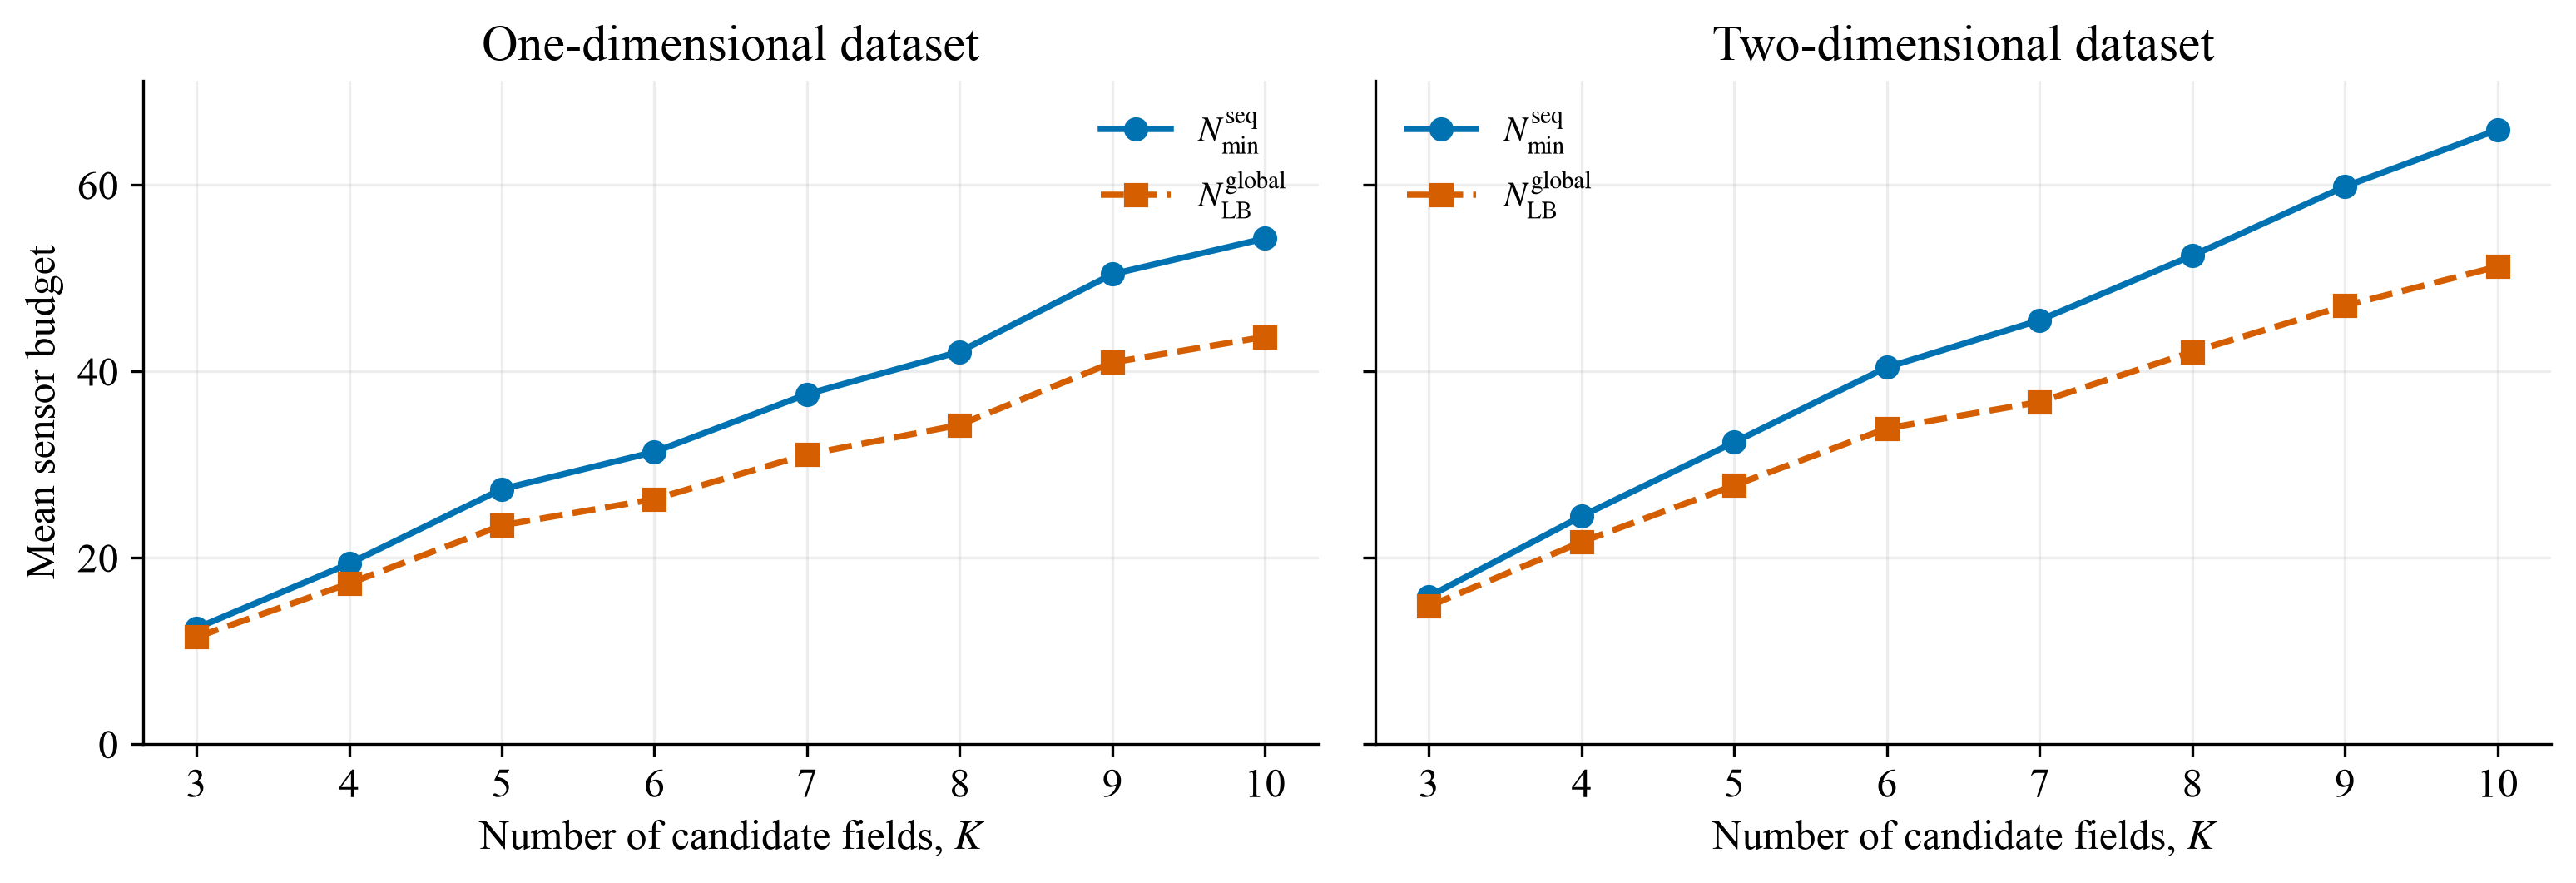

In [11]:
figure = plot_budget_comparison(summary)
if RUN_MODE == "test":
    figure.suptitle(f"Test run: {len(rows):,} cases (subset of benchmark)")
    figure.tight_layout(rect=(0, 0, 1, 0.94))
save_figure(figure, OUTPUT_DIRECTORY / "figures", "nlb_vs_nmin_by_k")
display(figure)
plt.close(figure)

## Saved outputs

- `tables/case_budgets.csv`: paired optima, allocations, input hashes, runtimes, ILP diagnostics and gaps.
- `tables/nlb_vs_nmin_by_dimension_k.csv`: main curve data.
- `tables/nlb_vs_nmin_by_k_m.csv`: results at fixed $K,M$.
- `figures/nlb_vs_nmin_by_k.{pdf,png}`.

Full outputs go to `results/lb/full/`. Test outputs go to `results/lb/test/` and do not overwrite full results.

`final_figures.ipynb` reads only the **full** summary. Run this notebook with `RUN_MODE = "full"` before assembling final figures.